# What real estate photography costs in the US (2026)

Published prices of **154 US real estate photographers and photo companies in 24 metros**, each read from the business's own pricing page on 3 November 2026. Dataset by [October](https://www.october-ai.com/data), CC BY 4.0, DOI [10.5281/zenodo.24324407](https://doi.org/10.5281/zenodo.24324407).

Questions answered below:
1. What does a standard photo package cost by home size?
2. How much do drone, video, twilight and 3D tour add-ons add?
3. How do metros compare?

Method notes: prices are as published (mostly "starting at"), before travel fees and taxes. Rows with `photo_only_package == False` bundle drone, video or 3D into the cheapest package, so they are left out of the package medians. An add-on price of 0 means "included" and is left out of the add-on medians.

In [1]:
import glob, os
import pandas as pd
import matplotlib.pyplot as plt

path = next(iter(glob.glob('/kaggle/input/**/photographer-prices.csv', recursive=True)), '../data/photographer-prices.csv')
df = pd.read_csv(path)
print(f"{len(df)} price lists, {df.metro.nunique()} metros, read {df.checked.min()} to {df.checked.max()}")
df.head()

154 price lists, 24 metros, read 2026-11-03 to 2026-11-03


,metro,business,url,checked,pricing_basis,photos_small_usd,small_tier,photos_medium_usd,medium_tier,photos_large_usd,large_tier,photos_included,turnaround,drone_addon_usd,video_addon_usd,twilight_addon_usd,tour_3d_addon_usd,photo_only_package,notes
0,Atlanta,360 and Back,https://www.360andback.com/,2026-11-03,sqft tiers,125.0,"0-1,499 sq ft base (residential photos from)",NaN,NaN,NaN,NaN,NaN,NaN,85.0,NaN,NaN,85.0,False,Only base tier priced; 'starting at'; drone fr...
1,Atlanta,Agents Choice Media,https://agentschoicemedia.com/real-estate-phot...,2026-11-03,flat package,NaN,NaN,249.0,"Essentials Showcase, starting at",NaN,NaN,NaN,same day / by 10 AM next day,NaN,NaN,NaN,NaN,False,Only 'starting at' package prices; Essentials ...
2,Atlanta,Carl Maynard Real Estate Photography (CM Real ...,https://cmrealphoto.com/protocol-%26-pricing,2026-11-03,flat package,NaN,NaN,175.0,"1,500-3,000 sq ft: $175-$225",NaN,NaN,40-50,NaN,NaN,NaN,NaN,NaN,True,Range not tiers; each project quoted; aerial i...
3,Atlanta,Clear Skies Real Estate Photography,https://www.clearskiesrealestatephotography.co...,2026-11-03,per photo,160.0,20 images,210.0,30 images,260.0,40 images,20-40,NaN,130.0,200.0,15.0,NaN,True,Tiers are image counts not sq ft (25 images $1...
4,Atlanta,Real Image Pros,https://www.realimagepros.com/pricing,2026-11-03,sqft tiers,199.0,"HDR Photography Unlimited, from (sq-ft based)",NaN,NaN,NaN,NaN,unlimited,next business day,50.0,399.0,10.0,125.0,True,"Only 'from' prices, sq ft tiers not shown; mul..."


## 1. Photo package price by home size

In [2]:
photo_only = df[df.photo_only_package == True]
tiers = {'Under 1,500 sq ft': 'photos_small_usd', '1,500–3,000 sq ft': 'photos_medium_usd', '3,000–4,500 sq ft': 'photos_large_usd'}
rows = []
for label, col in tiers.items():
    s = photo_only[col].dropna()
    rows.append({'home size': label, 'price lists': len(s), 'median $': s.median(), 'middle half $': f"{s.quantile(.25):.0f}–{s.quantile(.75):.0f}"})
pkg = pd.DataFrame(rows)
pkg

,home size,price lists,median $,middle half $
0,"Under 1,500 sq ft",88,189.0,150–225
1,"1,500–3,000 sq ft",105,225.0,195–264
2,"3,000–4,500 sq ft",73,290.0,235–350


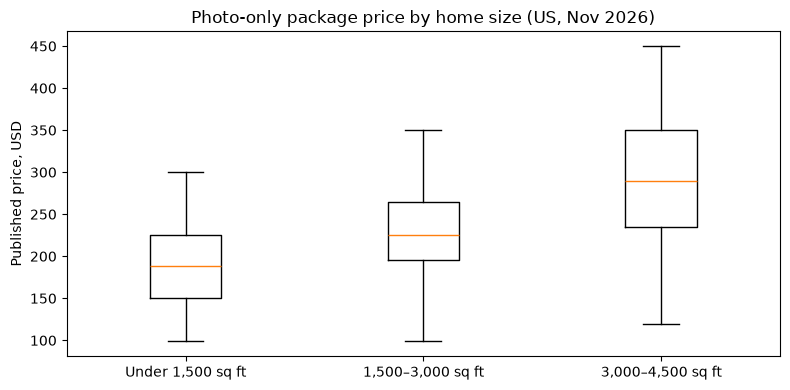

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([photo_only[c].dropna() for c in tiers.values()], showfliers=False)
ax.set_xticks([1, 2, 3], list(tiers.keys()))
ax.set_ylabel('Published price, USD')
ax.set_title('Photo-only package price by home size (US, Nov 2026)')
plt.tight_layout(); plt.show()

## 2. Add-ons

In [4]:
addons = {'Drone photos': 'drone_addon_usd', 'Walkthrough video': 'video_addon_usd', 'Twilight': 'twilight_addon_usd', '3D tour': 'tour_3d_addon_usd'}
rows = []
for label, col in addons.items():
    s = df[col].dropna(); s = s[s > 0]
    rows.append({'add-on': label, 'price lists': len(s), 'median $': s.median(), 'middle half $': f"{s.quantile(.25):.0f}–{s.quantile(.75):.0f}"})
pd.DataFrame(rows)

,add-on,price lists,median $,middle half $
0,Drone photos,101,129.0,95–150
1,Walkthrough video,98,275.0,200–350
2,Twilight,106,50.0,25–199
3,3D tour,81,199.0,150–250


Twilight mixes real dusk shoots with per-image virtual twilight edits (the `notes` column says which), which is why its spread is so wide.

## 3. By metro (1,500–3,000 sq ft, photo-only packages)

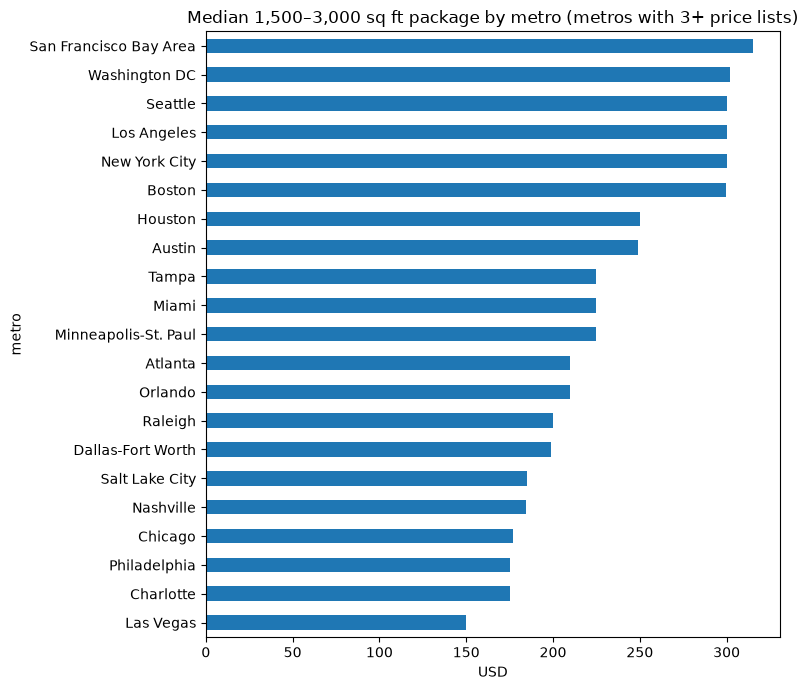

,count,median
metro,,
Las Vegas,5,150.0
Charlotte,3,175.0
Philadelphia,5,175.0
Chicago,4,177.0
Nashville,4,184.5
Salt Lake City,4,185.0
Dallas-Fort Worth,6,199.0
Raleigh,3,200.0
Orlando,6,209.5


In [5]:
m = (photo_only.dropna(subset=['photos_medium_usd'])
       .groupby('metro')['photos_medium_usd'].agg(['count', 'median'])
       .sort_values('median'))
m = m[m['count'] >= 3]
ax = m['median'].plot.barh(figsize=(8, 7), title='Median 1,500–3,000 sq ft package by metro (metros with 3+ price lists)')
ax.set_xlabel('USD'); plt.tight_layout(); plt.show()
m

## Takeaways

- A standard photo package for a 1,500–3,000 sq ft home has a median published price of about **$225**, and half of the price lists fall between about $195 and $264.
- Video is the most expensive common add-on. Drone and 3D tour add-ons usually cost less than the photos themselves.
- Metro medians rest on a few price lists each, so read them as a rough guide, not a price index.

Check `url` before relying on a row: prices change. Corrections are welcome on [GitHub](https://github.com/October-ai-jpg/listing-photo-data/issues).

*Source: October, october-ai.com/data*. More: [real estate photography pricing guide](https://www.october-ai.com/guides/real-estate-photography-cost).